In [1]:
%pip install pandas numpy matplotlib seaborn sqlalchemy pymysql

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   -- ------------------------------------- 0.8/10.9 MB 1.8 MB/s eta 0:00:06
   --- ------------------------------------ 1.0/10.9 MB 1.6 MB/s eta 0:00:07
   ---- ----------------------------------- 1.3/10.9 MB 1.7 MB/s eta 0:00:06
   ----- ---------------------------------- 1.6/10.9 MB 1.6 MB/s eta 0:00:06
   ------ --------------------------------- 1.8/10.9 MB 1.6 MB/s eta 0:00:06
   -------- ------------------------------- 2.4/10.9 MB 1.6 MB/s eta 0:00:06
   --------- ------------------------------ 2.6/10.9 MB 1.6 MB/s eta 0:00:06
   --------- ------------------------------ 2.6/10.9 MB 1.6 MB/s eta 0:00:06
   ---------- ----------------------------- 2.9/10.9 MB 1.4 MB/s eta 0:00:06
   ----------- ---------------------------- 3.1/10.9 MB 1.3 MB/s eta 0:00:06
   ------------ --------------------------- 3.4/10.9 MB 1.3 MB/s eta 0:00:06
   ----------


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# MySQL connection details
connection_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password="@Mandy307",
    host="127.0.0.1",
    port=3306,
    database="bank_db"
)

engine = create_engine(connection_url)

# Read the master view from MySQL
df = pd.read_sql(
    "SELECT * FROM vw_loan_master",
    engine
)

print("Data loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Data loaded successfully!
Dataset shape: (682, 31)


,loan_id,account_id,loan_date,amount,duration,payments,status,bad_loan,amount_band,age_at_loan,...,urban_ratio_pct,avg_salary,unemployment_rate_95,unemployment_rate_96,entrepreneurs_per_1000,crimes_95,crimes_96,client_id,gender,birth_date
0,4959,2,1994-01-05,80952,24,3373.0,A,0,Under 100k,48,...,100.0,12541,0.29,0.43,167,85677,99107,2,M,1945-02-04
1,4961,19,1996-04-29,30276,12,2523.0,B,1,Under 100k,57,...,67.0,9104,1.51,2.07,123,2299,2354,25,F,1939-04-23
2,4962,25,1997-12-08,30276,12,2523.0,A,0,Under 100k,35,...,57.2,9893,4.09,4.72,96,5623,5887,31,M,1962-02-09
3,4967,37,1998-10-14,318480,60,5308.0,D,1,Over 300k,46,...,58.4,8547,2.65,3.64,120,1563,1542,45,M,1952-08-26
4,4968,38,1998-04-19,110736,48,2307.0,C,0,100-200k,58,...,52.7,8402,3.13,3.98,120,999,1099,46,F,1940-01-30


In [5]:
# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# First five records
display(df.head())

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset Information:")
df.info()

# Statistical summary
display(df.describe(include="all").T)

# Missing values
print("\nMissing Values:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Rows: 682
Columns: 31


,loan_id,account_id,loan_date,amount,duration,payments,status,bad_loan,amount_band,age_at_loan,...,urban_ratio_pct,avg_salary,unemployment_rate_95,unemployment_rate_96,entrepreneurs_per_1000,crimes_95,crimes_96,client_id,gender,birth_date
0,4959,2,1994-01-05,80952,24,3373.0,A,0,Under 100k,48,...,100.0,12541,0.29,0.43,167,85677,99107,2,M,1945-02-04
1,4961,19,1996-04-29,30276,12,2523.0,B,1,Under 100k,57,...,67.0,9104,1.51,2.07,123,2299,2354,25,F,1939-04-23
2,4962,25,1997-12-08,30276,12,2523.0,A,0,Under 100k,35,...,57.2,9893,4.09,4.72,96,5623,5887,31,M,1962-02-09
3,4967,37,1998-10-14,318480,60,5308.0,D,1,Over 300k,46,...,58.4,8547,2.65,3.64,120,1563,1542,45,M,1952-08-26
4,4968,38,1998-04-19,110736,48,2307.0,C,0,100-200k,58,...,52.7,8402,3.13,3.98,120,999,1099,46,F,1940-01-30



Column Names:
['loan_id', 'account_id', 'loan_date', 'amount', 'duration', 'payments', 'status', 'bad_loan', 'amount_band', 'age_at_loan', 'district_id', 'account_frequency', 'account_open_date', 'district_name', 'region', 'inhabitants', 'municipalities_lt_499', 'municipalities_500_1999', 'municipalities_2000_9999', 'municipalities_gt_10000', 'cities', 'urban_ratio_pct', 'avg_salary', 'unemployment_rate_95', 'unemployment_rate_96', 'entrepreneurs_per_1000', 'crimes_95', 'crimes_96', 'client_id', 'gender', 'birth_date']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 682 entries, 0 to 681
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   loan_id                   682 non-null    int64  
 1   account_id                682 non-null    int64  
 2   loan_date                 682 non-null    object 
 3   amount                    682 non-null    int64  
 4   duration               

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
loan_id,682.0,NaN,NaN,NaN,6172.466276,682.579279,4959.0,5577.5,6176.5,6752.5,7308.0
account_id,682.0,NaN,NaN,NaN,5824.162757,3283.512681,2.0,2967.0,5738.5,8686.0,11362.0
loan_date,682,559,1998-04-19,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,682.0,NaN,NaN,NaN,151410.175953,113372.40631,4980.0,66732.0,116928.0,210654.0,590820.0
duration,682.0,NaN,NaN,NaN,36.492669,17.075219,12.0,24.0,36.0,48.0,60.0
payments,682.0,NaN,NaN,NaN,4190.664223,2215.830344,304.0,2477.0,3934.0,5813.5,9910.0
status,682,4,C,403,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bad_loan,682.0,NaN,NaN,NaN,0.111437,0.314903,0.0,0.0,0.0,0.0,1.0
amount_band,682,4,Under 100k,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_at_loan,682.0,NaN,NaN,NaN,37.630499,12.768289,13.0,27.0,37.0,48.0,61.0



Missing Values:


,missing_count
loan_id,0
account_id,0
loan_date,0
amount,0
duration,0
payments,0
status,0
bad_loan,0
amount_band,0
age_at_loan,0



Duplicate Rows: 0


In [6]:
#Clean the data and fix data types


# Keep an untouched copy for reconciliation
df_raw = df.copy()

# Replace '?' and whitespace-only strings with missing values
df = df.replace(r"^\s*\?\s*$", np.nan, regex=True)

# Strip extra spaces from text columns
object_cols = df.select_dtypes(include=["object", "string"]).columns

for col in object_cols:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Convert numeric columns when present
numeric_cols = [
    "loan_id",
    "account_id",
    "amount",
    "duration",
    "payments",
    "bad_loan",
    "age_at_loan",
    "district_id",
    "inhabitants",
    "cities",
    "avg_salary",
    "crimes_96",
    "client_id"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert date columns when present
date_cols = [
    "loan_date",
    "account_opening_date",
    "birth_date"
]

for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

print("Data cleaning completed.")

print("\nUpdated data types:")
print(df.dtypes)

print("\nMissing values after cleaning:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

Data cleaning completed.

Updated data types:
loan_id                             int64
account_id                          int64
loan_date                   datetime64[s]
amount                              int64
duration                            int64
payments                          float64
status                                str
bad_loan                            int64
amount_band                           str
age_at_loan                         int64
district_id                         int64
account_frequency                     str
account_open_date                  object
district_name                         str
region                                str
inhabitants                         int64
municipalities_lt_499               int64
municipalities_500_1999             int64
municipalities_2000_9999            int64
municipalities_gt_10000             int64
cities                              int64
urban_ratio_pct                   float64
avg_salary                    

,missing_count
crimes_95,8
unemployment_rate_95,8
loan_id,0
amount,0
duration,0
account_id,0
loan_date,0
bad_loan,0
amount_band,0
age_at_loan,0


In [7]:
#Create the three derived columns

# 1. Age Group
df["age_group"] = pd.cut(
    df["age_at_loan"],
    bins=[-np.inf, 29, 44, 59, np.inf],
    labels=["Under 30", "30-44", "45-59", "60+"]
)

# 2. Loan Term Band
# duration is measured in months
df["term_band"] = pd.cut(
    df["duration"],
    bins=[-np.inf, 12, 36, 60, np.inf],
    labels=["Up to 12 months",
            "13-36 months",
            "37-60 months",
            "Above 60 months"]
)

# 3. Loan Payments to District Average Salary
df["loan_to_salary"] = (
    df["payments"] /
    df["avg_salary"].replace(0, np.nan)
)

print("Derived columns created successfully.")

display(
    df[
        [
            col for col in [
                "age_at_loan",
                "age_group",
                "duration",
                "term_band",
                "payments",
                "avg_salary",
                "loan_to_salary"
            ]
            if col in df.columns
        ]
    ].head(10)
)

Derived columns created successfully.


,age_at_loan,age_group,duration,term_band,payments,avg_salary,loan_to_salary
0,48,45-59,24,13-36 months,3373.0,12541,0.268958
1,57,45-59,12,Up to 12 months,2523.0,9104,0.277131
2,35,30-44,12,Up to 12 months,2523.0,9893,0.255029
3,46,45-59,60,37-60 months,5308.0,8547,0.621037
4,58,45-59,48,37-60 months,2307.0,8402,0.274577
5,51,45-59,24,13-36 months,6915.0,8427,0.820577
6,55,45-59,12,Up to 12 months,8573.0,10673,0.803242
7,30,30-44,36,13-36 months,7370.0,8254,0.892900
8,47,45-59,48,37-60 months,7348.0,9104,0.807118
9,44,30-44,36,13-36 months,4516.0,9198,0.490976


In [ ]:
#Create five charts

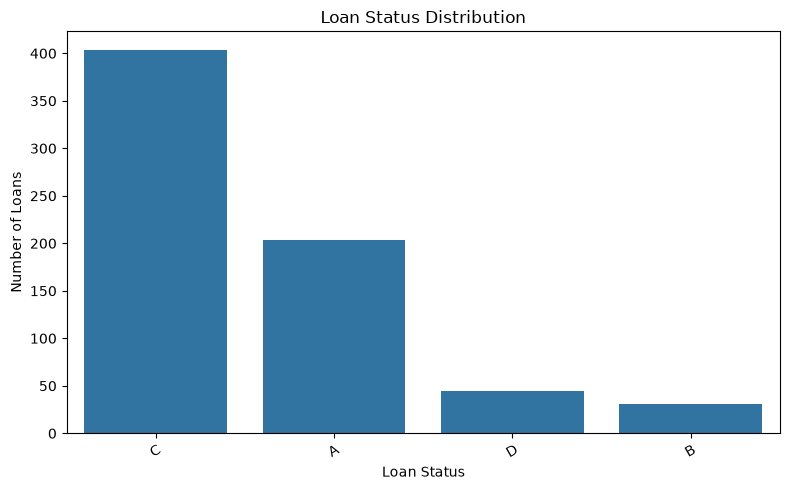

In [8]:
#Loan Status Distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="status",
    order=df["status"].value_counts().index
)

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

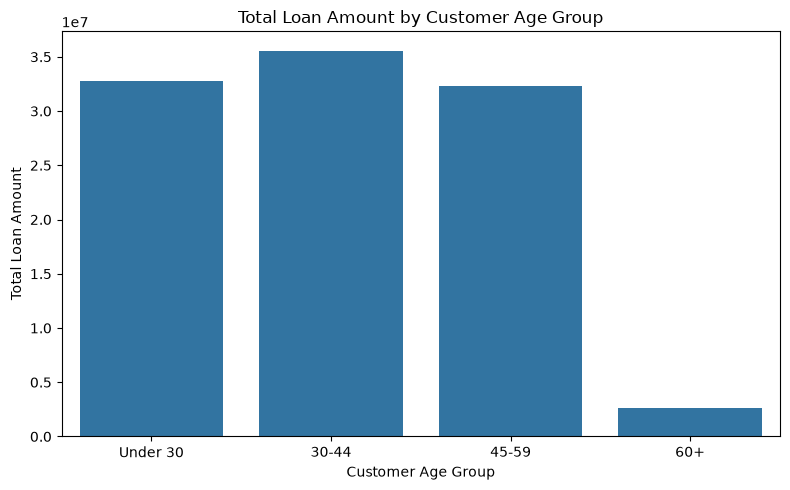

In [9]:
# Loan Amount by Age Group

age_loan = (
    df.groupby("age_group", observed=False)["amount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_loan,
    x="age_group",
    y="amount"
)

plt.title("Total Loan Amount by Customer Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Total Loan Amount")
plt.tight_layout()
plt.show()

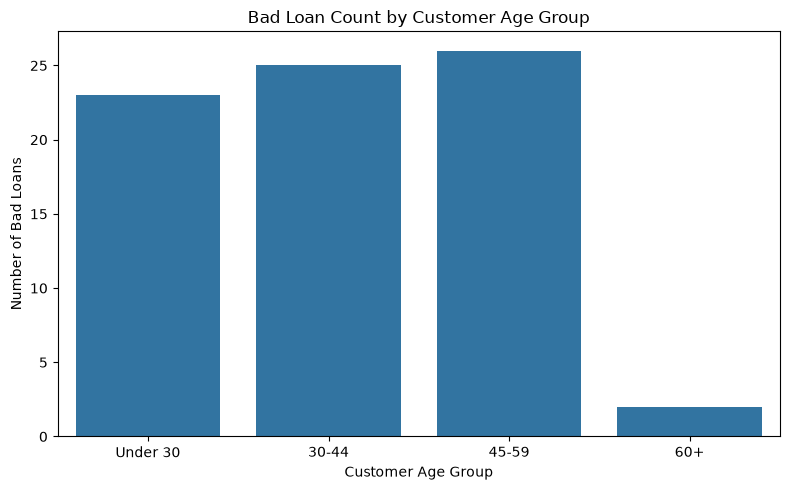

In [10]:
# Bad Loan Count by Age Group

age_risk = (
    df.groupby("age_group", observed=False)["bad_loan"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_risk,
    x="age_group",
    y="bad_loan"
)

plt.title("Bad Loan Count by Customer Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Number of Bad Loans")
plt.tight_layout()
plt.show()

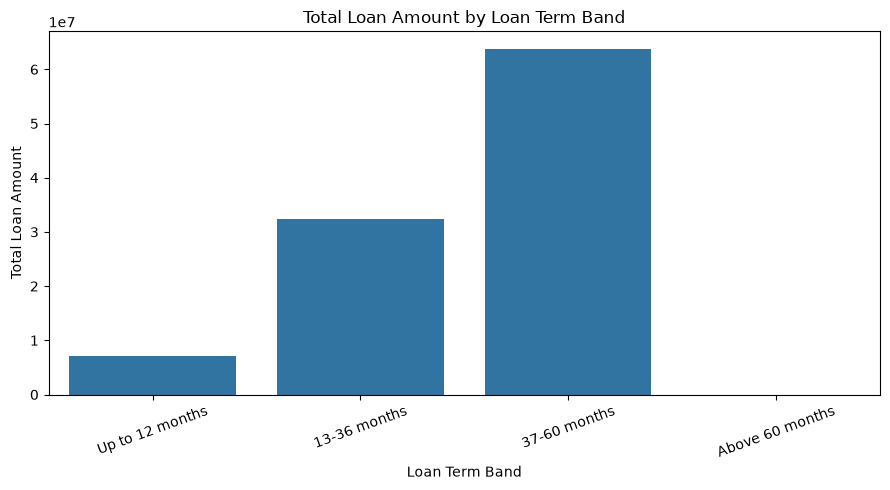

In [11]:
# Loan Amount by Term Band

term_loan = (
    df.groupby("term_band", observed=False)["amount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=term_loan,
    x="term_band",
    y="amount"
)

plt.title("Total Loan Amount by Loan Term Band")
plt.xlabel("Loan Term Band")
plt.ylabel("Total Loan Amount")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

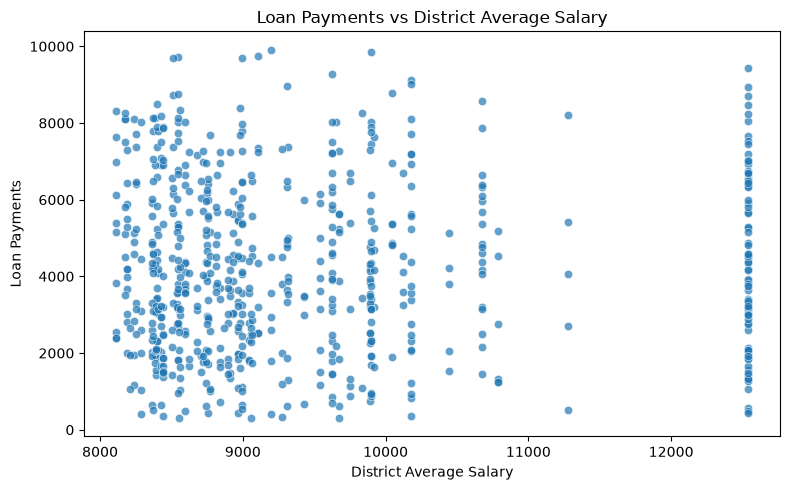

In [12]:
# Loan Payments vs District Average Salary

plot_df = df[
    ["avg_salary", "payments", "loan_to_salary"]
].dropna()

plot_df = plot_df[
    (plot_df["avg_salary"] > 0) &
    (plot_df["payments"] >= 0)
]

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_df,
    x="avg_salary",
    y="payments",
    alpha=0.7
)

plt.title("Loan Payments vs District Average Salary")
plt.xlabel("District Average Salary")
plt.ylabel("Loan Payments")
plt.tight_layout()
plt.show()

## Key Observations

### 1. Loan Status
The distribution of loans varies across different loan statuses.

### 2. Customer Age Group
Loan distribution varies across customer age groups.

### 3. Loan Risk
The proportion of bad loans differs across customer age groups.

In [13]:
# Reconciliation numbers


print("=" * 45)
print("RECONCILIATION REPORT")
print("=" * 45)

print("Original dataset shape:", df_raw.shape)
print("Cleaned dataset shape:", df.shape)

print("\nOriginal row count:", len(df_raw))
print("Cleaned row count:", len(df))

print("\nOriginal duplicate rows:",
      df_raw.duplicated().sum())

print("Cleaned duplicate rows:",
      df.duplicated().sum())

print("\nMissing values before cleaning:",
      df_raw.isnull().sum().sum())

print("Missing values after cleaning:",
      df.isnull().sum().sum())

if "loan_id" in df.columns:
    print("\nUnique loan IDs:", df["loan_id"].nunique())

if "amount" in df.columns:
    print("Total loan amount:", df["amount"].sum())

if "bad_loan" in df.columns:
    print("Total bad loans:", df["bad_loan"].sum())

print("\nReconciliation report completed.")

RECONCILIATION REPORT
Original dataset shape: (682, 31)
Cleaned dataset shape: (682, 34)

Original row count: 682
Cleaned row count: 682

Original duplicate rows: 0
Cleaned duplicate rows: 0

Missing values before cleaning: 0
Missing values after cleaning: 16

Unique loan IDs: 682
Total loan amount: 103261740
Total bad loans: 76

Reconciliation report completed.


In [14]:
df.to_csv("loan_master_clean.csv", index=False)

print("loan_master_clean.csv saved successfully!")

loan_master_clean.csv saved successfully!


In [15]:
import os

print("Saved file location:")
print(os.path.abspath("loan_master_clean.csv"))

print("\nFile exists:", os.path.exists("loan_master_clean.csv"))

Saved file location:
c:\Users\dkart\AppData\Local\Programs\Microsoft VS Code\loan_master_clean.csv

File exists: True


In [16]:
df.to_sql(
    name="loan_master_clean",
    con=engine,
    if_exists="replace",
    index=False
)

print("loan_master_clean table saved successfully!")

loan_master_clean table saved successfully!
